In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/customer_support_tickets.csv")

df.head()

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


In [2]:
df.shape

(8469, 17)

In [3]:
df.columns.tolist()

['Ticket ID',
 'Customer Name',
 'Customer Email',
 'Customer Age',
 'Customer Gender',
 'Product Purchased',
 'Date of Purchase',
 'Ticket Type',
 'Ticket Subject',
 'Ticket Description',
 'Ticket Status',
 'Resolution',
 'Ticket Priority',
 'Ticket Channel',
 'First Response Time',
 'Time to Resolution',
 'Customer Satisfaction Rating']

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Name                 8469 non-null   object 
 2   Customer Email                8469 non-null   object 
 3   Customer Age                  8469 non-null   int64  
 4   Customer Gender               8469 non-null   object 
 5   Product Purchased             8469 non-null   object 
 6   Date of Purchase              8469 non-null   object 
 7   Ticket Type                   8469 non-null   object 
 8   Ticket Subject                8469 non-null   object 
 9   Ticket Description            8469 non-null   object 
 10  Ticket Status                 8469 non-null   object 
 11  Resolution                    2769 non-null   object 
 12  Ticket Priority               8469 non-null   object 
 13  Tic

In [5]:
df.isnull().sum()

Ticket ID                          0
Customer Name                      0
Customer Email                     0
Customer Age                       0
Customer Gender                    0
Product Purchased                  0
Date of Purchase                   0
Ticket Type                        0
Ticket Subject                     0
Ticket Description                 0
Ticket Status                      0
Resolution                      5700
Ticket Priority                    0
Ticket Channel                     0
First Response Time             2819
Time to Resolution              5700
Customer Satisfaction Rating    5700
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.nunique()

Ticket ID                       8469
Customer Name                   8028
Customer Email                  8320
Customer Age                      53
Customer Gender                    3
Product Purchased                 42
Date of Purchase                 730
Ticket Type                        5
Ticket Subject                    16
Ticket Description              8077
Ticket Status                      3
Resolution                      2769
Ticket Priority                    4
Ticket Channel                     4
First Response Time             5470
Time to Resolution              2728
Customer Satisfaction Rating       5
dtype: int64

In [8]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Ticket ID,8469.0,NaN,NaN,NaN,4235.0,2444.934048,1.0,2118.0,4235.0,6352.0,8469.0
Customer Name,8469,8028,Michael Garcia,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Email,8469,8320,bsmith@example.com,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Age,8469.0,NaN,NaN,NaN,44.026804,15.296112,18.0,31.0,44.0,57.0,70.0
Customer Gender,8469,3,Male,2896,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Purchased,8469,42,Canon EOS,240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date of Purchase,8469,730,2020-10-21,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket Type,8469,5,Refund request,1752,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket Subject,8469,16,Refund request,576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket Description,8469,8077,I'm having an issue with the {product_purchase...,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# Make a working copy
clean_df = df.copy()

# Convert date columns
clean_df["Date of Purchase"] = pd.to_datetime(
    clean_df["Date of Purchase"],
    errors="coerce"
)

clean_df["First Response Time"] = pd.to_datetime(
    clean_df["First Response Time"],
    errors="coerce"
)

clean_df["Time to Resolution"] = pd.to_datetime(
    clean_df["Time to Resolution"],
    errors="coerce"
)

clean_df.head()

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaT,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaT,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


In [10]:
# Check ticket status values
clean_df["Ticket Status"].value_counts()

Ticket Status
Pending Customer Response    2881
Open                         2819
Closed                       2769
Name: count, dtype: int64

In [11]:
# Check priority values
clean_df["Ticket Priority"].value_counts()

Ticket Priority
Medium      2192
Critical    2129
High        2085
Low         2063
Name: count, dtype: int64

In [12]:
# Check ticket channel values
clean_df["Ticket Channel"].value_counts()

Ticket Channel
Email           2143
Phone           2132
Social media    2121
Chat            2073
Name: count, dtype: int64

In [13]:
# Check ticket type values
clean_df["Ticket Type"].value_counts()

Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64

In [14]:
# Check CSAT distribution
clean_df["Customer Satisfaction Rating"].value_counts(
    dropna=False
).sort_index()

Customer Satisfaction Rating
1.0     553
2.0     549
3.0     580
4.0     543
5.0     544
NaN    5700
Name: count, dtype: int64

In [15]:
# Closed ticket flag
clean_df["Is Closed"] = clean_df["Ticket Status"].eq("Closed")

# Resolution rate
resolution_rate = clean_df["Is Closed"].mean() * 100

# Average CSAT for tickets with a rating
avg_csat = clean_df["Customer Satisfaction Rating"].mean()

resolution_rate, avg_csat

(np.float64(32.69571377966702), np.float64(2.991332611050921))

In [16]:
# Convert response and resolution timestamps to datetime
clean_df["First Response Time"] = pd.to_datetime(
    clean_df["First Response Time"],
    errors="coerce"
)

clean_df["Time to Resolution"] = pd.to_datetime(
    clean_df["Time to Resolution"],
    errors="coerce"
)

# Create elapsed hours from purchase date
clean_df["First Response Hours"] = (
    clean_df["First Response Time"] - clean_df["Date of Purchase"]
).dt.total_seconds() / 3600

clean_df["Resolution Hours"] = (
    clean_df["Time to Resolution"] - clean_df["Date of Purchase"]
).dt.total_seconds() / 3600

In [17]:
clean_df[
    [
        "Date of Purchase",
        "First Response Time",
        "Time to Resolution",
        "First Response Hours",
        "Resolution Hours",
    ]
].head(10)

,Date of Purchase,First Response Time,Time to Resolution,First Response Hours,Resolution Hours
0,2021-03-22,2023-06-01 12:15:36,NaT,19236.260000,NaN
1,2021-05-22,2023-06-01 16:45:38,NaT,17776.760556,NaN
2,2020-07-14,2023-06-01 11:14:38,2023-06-01 18:05:38,25259.243889,25266.093889
3,2020-11-13,2023-06-01 07:29:40,2023-06-01 01:57:40,22327.494444,22321.961111
4,2020-02-04,2023-06-01 00:12:42,2023-06-01 19:53:42,29112.211667,29131.895000
5,2020-07-28,NaT,NaT,NaN,NaN
6,2020-02-23,NaT,NaT,NaN,NaN
7,2020-08-09,NaT,NaT,NaN,NaN
8,2020-07-16,2023-06-01 10:32:47,NaT,25210.546389,NaN
9,2020-03-06,2023-06-01 09:25:48,NaT,28377.430000,NaN


In [18]:
clean_df[
    [
        "First Response Hours",
        "Resolution Hours",
    ]
].describe()

,First Response Hours,Resolution Hours
count,5650.000000,2769.000000
mean,21232.951597,21234.361898
std,5085.304886,5075.863353
min,12435.146111,12438.464444
25%,16824.263403,16808.266111
50%,21273.225972,21306.388056
75%,25629.607569,25613.881944
max,29944.581944,29947.068889


In [19]:
# =========================================================
# SAFE KPI METRICS
# =========================================================

total_tickets = len(clean_df)

closed_tickets = (
    clean_df["Ticket Status"]
    .eq("Closed")
    .sum()
)

open_tickets = (
    clean_df["Ticket Status"]
    .eq("Open")
    .sum()
)

pending_tickets = (
    clean_df["Ticket Status"]
    .eq("Pending Customer Response")
    .sum()
)

resolution_rate = (
    closed_tickets / total_tickets
) * 100

avg_csat = (
    clean_df["Customer Satisfaction Rating"]
    .mean()
)

print("Total Tickets:", total_tickets)
print("Closed Tickets:", closed_tickets)
print("Open Tickets:", open_tickets)
print("Pending Tickets:", pending_tickets)
print(f"Resolution Rate: {resolution_rate:.2f}%")
print(f"Average CSAT: {avg_csat:.2f}/5")

Total Tickets: 8469
Closed Tickets: 2769
Open Tickets: 2819
Pending Tickets: 2881
Resolution Rate: 32.70%
Average CSAT: 2.99/5


In [20]:
# Remove the misleading derived time columns
clean_df = clean_df.drop(
    columns=[
        "First Response Hours",
        "Resolution Hours",
    ],
    errors="ignore",
)

# Save cleaned data for Streamlit dashboard
clean_df.to_csv(
    "../data/customer_support_clean.csv",
    index=False,
)

print("Saved cleaned dataset.")
print(clean_df.shape)

Saved cleaned dataset.
(8469, 18)


In [21]:
clean_df.head()

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating,Is Closed
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaT,NaN,False
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaT,NaN,False
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0,True
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0,True
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0,True


In [32]:
# =========================================================
# TICKETS BY STATUS
# =========================================================

status_counts = (
    clean_df["Ticket Status"]
    .value_counts()
    .reset_index()
)

status_counts.columns = [
    "Ticket Status",
    "Ticket Count",
]

status_counts

,Ticket Status,Ticket Count
0,Pending Customer Response,2881
1,Open,2819
2,Closed,2769


In [23]:
# =========================================================
# TICKETS BY PRIORITY
# =========================================================

priority_counts = (
    clean_df["Ticket Priority"]
    .value_counts()
    .reset_index()
)

priority_counts.columns = [
    "Ticket Priority",
    "Ticket Count",
]

priority_counts

,Ticket Priority,Ticket Count
0,Medium,2192
1,Critical,2129
2,High,2085
3,Low,2063


In [24]:
# =========================================================
# TICKETS BY CHANNEL
# =========================================================

channel_counts = (
    clean_df["Ticket Channel"]
    .value_counts()
    .reset_index()
)

channel_counts.columns = [
    "Ticket Channel",
    "Ticket Count",
]

channel_counts

,Ticket Channel,Ticket Count
0,Email,2143
1,Phone,2132
2,Social media,2121
3,Chat,2073


In [25]:
# =========================================================
# TICKETS BY TYPE
# =========================================================

type_counts = (
    clean_df["Ticket Type"]
    .value_counts()
    .reset_index()
)

type_counts.columns = [
    "Ticket Type",
    "Ticket Count",
]

type_counts

,Ticket Type,Ticket Count
0,Refund request,1752
1,Technical issue,1747
2,Cancellation request,1695
3,Product inquiry,1641
4,Billing inquiry,1634


In [26]:
# =========================================================
# CSAT BY TICKET TYPE
# =========================================================

csat_by_type = (
    clean_df
    .groupby("Ticket Type")["Customer Satisfaction Rating"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

csat_by_type

,Ticket Type,Customer Satisfaction Rating
0,Cancellation request,3.029070
1,Billing inquiry,3.027574
2,Product inquiry,3.016886
3,Technical issue,2.958621
4,Refund request,2.934564


In [27]:
# =========================================================
# CSAT BY PRIORITY
# =========================================================

csat_by_priority = (
    clean_df
    .groupby("Ticket Priority")["Customer Satisfaction Rating"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

csat_by_priority

,Ticket Priority,Customer Satisfaction Rating
0,Low,3.052795
1,High,2.982979
2,Medium,2.976945
3,Critical,2.958678


In [28]:
# =========================================================
# CSAT BY CHANNEL
# =========================================================

csat_by_channel = (
    clean_df
    .groupby("Ticket Channel")["Customer Satisfaction Rating"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

csat_by_channel

,Ticket Channel,Customer Satisfaction Rating
0,Chat,3.083086
1,Social media,2.969298
2,Email,2.963889
3,Phone,2.952243


In [29]:
# =========================================================
# CSAT DISTRIBUTION
# =========================================================

csat_distribution = (
    clean_df["Customer Satisfaction Rating"]
    .value_counts()
    .sort_index()
    .reset_index()
)

csat_distribution.columns = [
    "CSAT Rating",
    "Ticket Count",
]

csat_distribution

,CSAT Rating,Ticket Count
0,1.0,553
1,2.0,549
2,3.0,580
3,4.0,543
4,5.0,544


In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

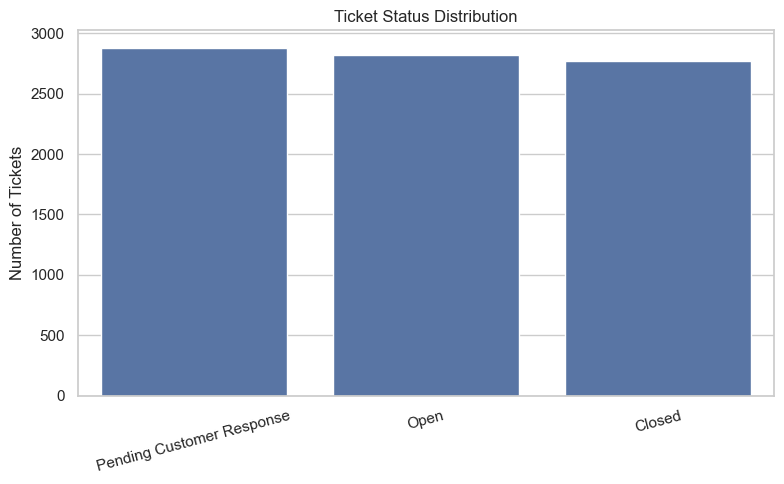

In [33]:
# =========================================================
# 1. TICKET STATUS DISTRIBUTION
# =========================================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=status_counts,
    x="Ticket Status",
    y="Ticket Count",
)

plt.title("Ticket Status Distribution")
plt.xlabel("")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

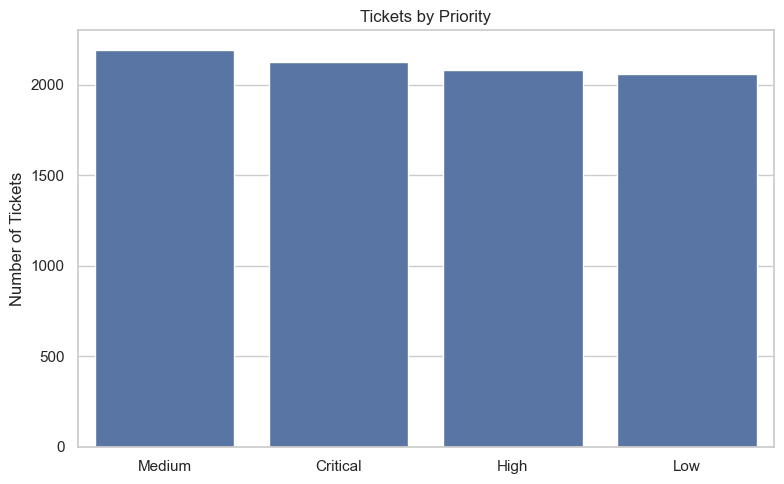

In [35]:
# =========================================================
# 2. TICKETS BY PRIORITY
# =========================================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=priority_counts,
    x="Ticket Priority",
    y="Ticket Count",
)

plt.title("Tickets by Priority")
plt.xlabel("")
plt.ylabel("Number of Tickets")
plt.tight_layout()
plt.show()

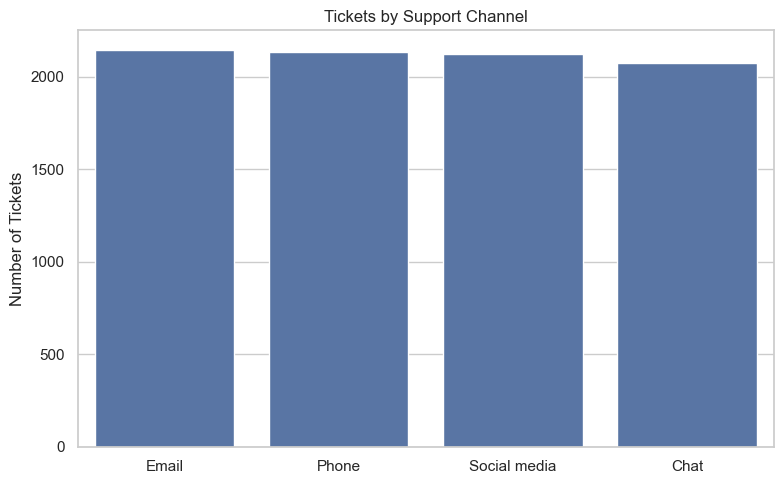

In [36]:
# =========================================================
# 3. TICKETS BY CHANNEL
# =========================================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=channel_counts,
    x="Ticket Channel",
    y="Ticket Count",
)

plt.title("Tickets by Support Channel")
plt.xlabel("")
plt.ylabel("Number of Tickets")
plt.tight_layout()
plt.show()

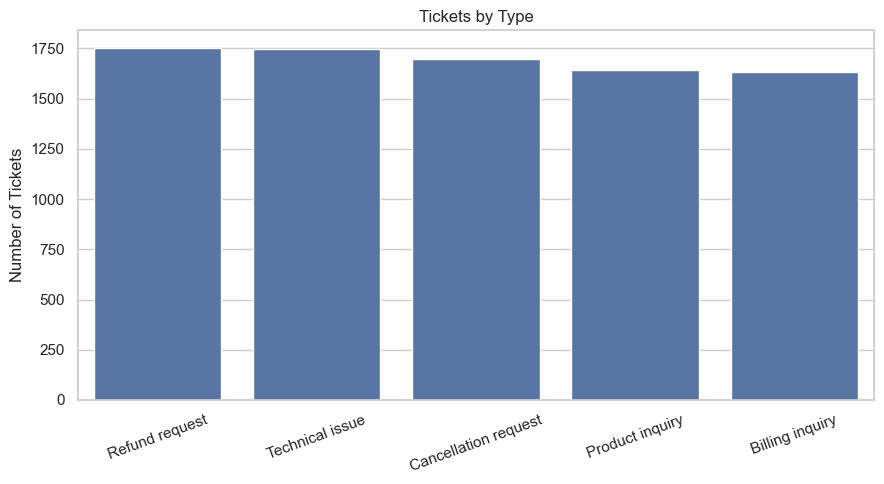

In [38]:
# =========================================================
# 4. TICKETS BY TYPE
# =========================================================

plt.figure(figsize=(9, 5))

sns.barplot(
    data=type_counts,
    x="Ticket Type",
    y="Ticket Count",
)

plt.title("Tickets by Type")
plt.xlabel("")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

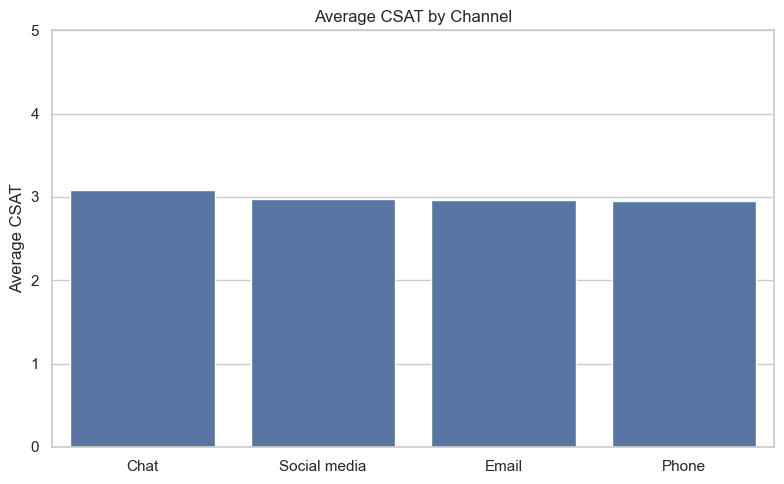

In [39]:
# =========================================================
# 5. CSAT BY CHANNEL
# =========================================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=csat_by_channel,
    x="Ticket Channel",
    y="Customer Satisfaction Rating",
)

plt.title("Average CSAT by Channel")
plt.xlabel("")
plt.ylabel("Average CSAT")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

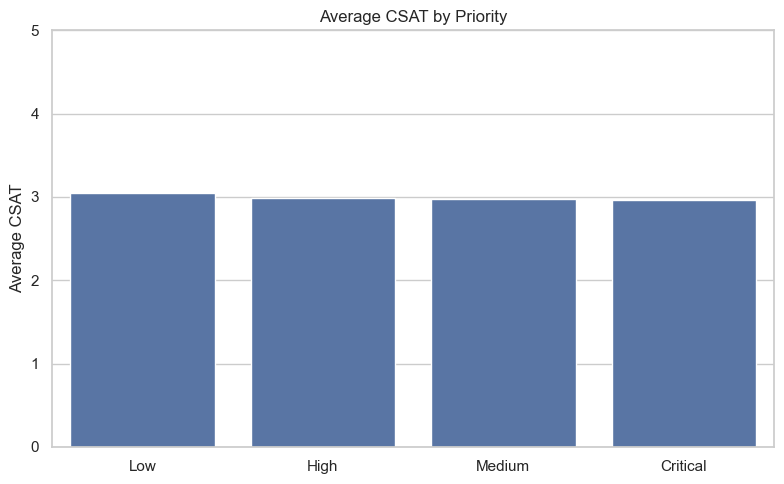

In [40]:
# =========================================================
# 6. CSAT BY PRIORITY
# =========================================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=csat_by_priority,
    x="Ticket Priority",
    y="Customer Satisfaction Rating",
)

plt.title("Average CSAT by Priority")
plt.xlabel("")
plt.ylabel("Average CSAT")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

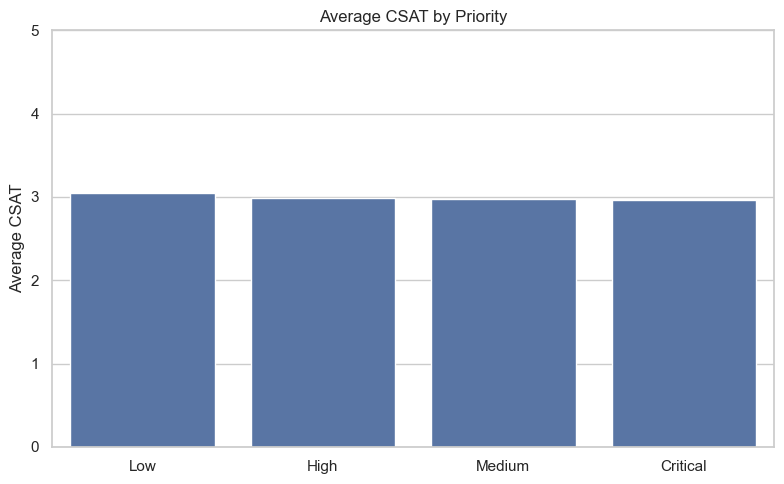

In [41]:
# =========================================================
# 6. CSAT BY PRIORITY
# =========================================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=csat_by_priority,
    x="Ticket Priority",
    y="Customer Satisfaction Rating",
)

plt.title("Average CSAT by Priority")
plt.xlabel("")
plt.ylabel("Average CSAT")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

## Business Insights

- Ticket volume is relatively balanced across statuses, with **Pending Customer Response** representing the largest group.
- **Medium-priority tickets** have the highest ticket count, although the overall priority distribution is fairly even.
- **Email** is the most frequently used support channel, followed closely by Phone and Social Media.
- **Refund requests** are the most common ticket type, with Technical Issues close behind.
- Customer satisfaction is relatively stable across categories, averaging around **3 out of 5**.
- **Chat** has the highest average CSAT, while **Phone** has the lowest.
- **Low-priority tickets** have slightly higher satisfaction than Critical, High, and Medium priority tickets.
- Because the dataset does not contain a true ticket creation timestamp, purchase dates were not used to calculate support response or resolution duration metrics.